# Cross-platform replication of DenMark rho  (Visium HD vs Xenium v1 vs Xenium 5K)

**Fixed 30×30 grid on every platform** (matches the converged HD run: `FORCE_NXNY=(30,30)`).
Because DenMark normalises tile coordinates by the grid pitch, a fixed 30×30 grid makes rho
**scale-invariant** across technologies.

HD is **refit on each intersected panel** so ρ is like-for-like.

**Outputs:** panel-overlap summary, per-platform tumour-mask QC maps, paired
forests (HD–v1, HD–5K).

In [ ]:
# === CONFIGURE ME ===
DATA_DIR = '../../data'      # holds the annotated Visium HD object and the Xenium v1 and 5K folders (see README.md)
OUTPUT_DIR = '../../output'  # results go to xplatform_out/ and CmdStan files to stan_out/ below it
REPO_ROOT = '../..'          # root of the DenMark checkout, holds inst/stan/ (defaults assume Jupyter starts in this folder)
# ====================

## 0. figure defaults

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scanpy as sc
from scipy.spatial import Delaunay, cKDTree
from scipy.spatial.distance import pdist
import matplotlib as mpl

# Figure-style: Arial, small type, thin lines, no top/right spines, high dpi
mpl.rcParams.update({
    "font.family":"sans-serif", "font.sans-serif":["Arial","Helvetica","DejaVu Sans"],
    "font.size":7, "axes.labelsize":7, "axes.titlesize":8, "xtick.labelsize":6,
    "ytick.labelsize":6, "legend.fontsize":6, "axes.linewidth":0.6, "xtick.major.width":0.6,
    "ytick.major.width":0.6, "axes.spines.top":False, "axes.spines.right":False,
    "figure.dpi":140, "savefig.dpi":300, "savefig.bbox":"tight", "lines.linewidth":1.0,
})
PLAT_COLORS = {"HD":"#3b6fb6", "v1":"#d1743c", "5K":"#4c9a6b"}   # muted, colourblind-safe

## 1. Load the three platforms  (raw Xenium folders + HD h5ad)

**Xenium** (v1, 5K):
1. reads `cell_feature_matrix.h5` with `scanpy.read_10x_h5` and keeps only **Gene Expression**
   features (drops Negative-Control probes / blank / unassigned / deprecated codewords);
2. reads `cells.parquet` for `x_centroid, y_centroid` — **already in microns** on Xenium;
3. aligns the cell table to the matrix by `cell_id`, stores coords in `obsm['spatial']`, raw
   integer counts in `layers['counts']`, and upper-cases gene symbols for cross-platform matching.

**HD**: Annotated `.h5ad`. Coords are rebuilt from `obs['x_centroid/y_centroid'] × MPP_HD`
to mirror the main pipeline. (Under the fixed 30×30 grid, `MPP_HD` only affects the *printed*
pitch, not ρ — see the title note — so an approximate value is fine.)

*Requires `pyarrow` for parquet (`pip install pyarrow`) — already present if the HD pipeline read parquet.*

In [3]:
from pathlib import Path

# ── point these at YOUR paths ────────────────────────────────────────────────
HD_H5AD = Path(f"{DATA_DIR}/visium_ovarian/results/tables/visium_hd_ovarian_cancer_annotated.h5ad")   # main-pipeline HD object
MPP_HD  = 1.0     # microns-per-pixel from the HD pipeline printout. Under a fixed 30x30 grid this
                  # only rescales the reported pitch, not rho. Leave 1.0 if HD coords already in µm.

# Xenium raw-output FOLDERS (the folder that directly holds cell_feature_matrix.h5 + cells.parquet)
XENIUM_V1_DIR = Path(f"{DATA_DIR}/Revision-R1/VisiumHD-Breast_Cancer/Xenium V1")   
XENIUM_5K_DIR = Path(f"{DATA_DIR}/Revision-R1/VisiumHD-Breast_Cancer/Xenium 5K")  

COORD_KEY, COUNTS_LAYER, CELL_TYPE_COL = "spatial", "counts", "cell_type"

def load_xenium(folder):
    """Raw Xenium Onboard-Analysis folder -> AnnData (genes only, µm coords, raw counts)."""
    folder = Path(folder)
    h5 = folder / "cell_feature_matrix.h5"
    assert h5.exists(), f"cell_feature_matrix.h5 not found in {folder}"
    try:    a = sc.read_10x_h5(str(h5), gex_only=False)
    except TypeError: a = sc.read_10x_h5(str(h5))
    if "feature_types" in a.var:                          # drop control / blank / codeword features
        a = a[:, a.var["feature_types"].astype(str) == "Gene Expression"].copy()
    a.var_names_make_unique()
    cfp = folder / "cells.parquet"
    cells = pd.read_parquet(cfp) if cfp.exists() else pd.read_csv(folder / "cells.csv.gz")
    idcol = "cell_id" if "cell_id" in cells.columns else cells.columns[0]
    cells = cells.set_index(idcol)
    common = a.obs_names.intersection(cells.index)
    if len(common) >= 0.99 * a.n_obs:                     # align by cell_id
        cells = cells.loc[a.obs_names]
    else:                                                 # Xenium keeps row order -> positional
        assert len(cells) == a.n_obs, "cells table length != matrix n_obs; cannot align"
        cells = cells.iloc[:a.n_obs]; cells.index = a.obs_names
    xy = cells[["x_centroid", "y_centroid"]].to_numpy(float)      # ALREADY microns
    a.obsm[COORD_KEY] = xy
    a.obs["x_centroid"], a.obs["y_centroid"] = xy[:, 0], xy[:, 1]
    a.layers[COUNTS_LAYER] = a.X.copy()                   # raw integer counts
    a.var_names = a.var_names.str.upper()
    return a

def load_hd(h5ad, mpp=1.0):
    a = sc.read_h5ad(h5ad)
    a.var_names = a.var_names.str.upper()
    if COUNTS_LAYER not in a.layers:
        a.layers[COUNTS_LAYER] = a.X.copy()
    if COORD_KEY in a.obsm and mpp == 1.0:
        pass                                              # already microns
    else:
        assert {"x_centroid", "y_centroid"} <= set(a.obs.columns), \
            "HD object lacks obs x_centroid/y_centroid and a µm obsm['spatial']"
        a.obsm[COORD_KEY] = np.column_stack([a.obs["x_centroid"].to_numpy(float),
                                             a.obs["y_centroid"].to_numpy(float)]) * mpp
    return a

adatas = {"HD": load_hd(HD_H5AD, MPP_HD),
          "v1": load_xenium(XENIUM_V1_DIR),
          "5K": load_xenium(XENIUM_5K_DIR)}
for plat, a in adatas.items():
    xy = np.asarray(a.obsm[COORD_KEY])[:, :2]
    print(f"{plat:3s}: {a.n_obs:>8,} cells | {a.n_vars:>5} genes | "
          f"extent {np.ptp(xy[:,0]):>6.0f} x {np.ptp(xy[:,1]):>6.0f} µm | "
          f"counts-layer={COUNTS_LAYER in a.layers} | µm/tile≈{np.ptp(xy[:,0])/30:.0f}x{np.ptp(xy[:,1])/30:.0f}")

HD :  181,179 cells | 16675 genes | extent  24444 x  24660 µm | counts-layer=True | µm/tile≈815x822
v1 :  205,082 cells |   477 genes | extent   7821 x   7034 µm | counts-layer=True | µm/tile≈261x234
5K :  200,900 cells |  5001 genes | extent   7766 x   7171 µm | counts-layer=True | µm/tile≈259x239


    genes   cells  depth
HD  16675  181179  3,317
5K   5001  200900  1,283
v1    477  205082    595


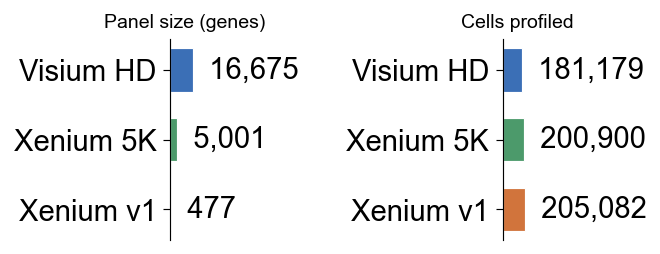

In [4]:
# ═══ Dataset summary subpanel: genes & cells across platforms ═══
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
OUT_DIR = globals().get("OUT_DIR", Path(f"{OUTPUT_DIR}/xplatform_out")); OUT_DIR.mkdir(parents=True, exist_ok=True)

PLAT_ORDER = ["HD", "5K", "v1"]
PLAT_LABEL = {"HD": "Visium HD", "5K": "Xenium 5K", "v1": "Xenium v1"}
try:    COL = {p: PLAT_COLORS[p] for p in PLAT_ORDER}
except NameError: COL = {"HD": "#4c72b0", "5K": "#55a868", "v1": "#c44e52"}

def _median_depth(a):
    X = a.layers[COUNTS_LAYER] if (COUNTS_LAYER in a.layers) else a.X
    return float(np.median(np.asarray(X.sum(1)).ravel()))

summ = pd.DataFrame({
    "genes": {p: int(adatas[p].n_vars) for p in PLAT_ORDER},
    "cells": {p: int(adatas[p].n_obs)  for p in PLAT_ORDER},
    "depth": {p: _median_depth(adatas[p]) for p in PLAT_ORDER},   # median transcripts / cell
}).loc[PLAT_ORDER]
print(summ.to_string(float_format=lambda v: f"{v:,.0f}"))

# metrics to draw — genes + cells as requested; uncomment depth for a 3rd panel
METRICS = [("genes", "Panel size (genes)", "{:,.0f}"),
           ("cells", "Cells profiled",     "{:,.0f}")]

def _barh(ax, vals, title, fmt):
    y = np.arange(len(PLAT_ORDER))[::-1]                 # HD on top
    ax.barh(y, vals, height=0.62, color=[COL[p] for p in PLAT_ORDER],
            edgecolor="white", linewidth=0.6)
    for yi, v in zip(y, vals):
        ax.text(v, yi, "  " + fmt.format(v), va="center", ha="left", fontsize=15)
    ax.set_yticks(y); ax.set_yticklabels([PLAT_LABEL[p] for p in PLAT_ORDER], fontsize=15)
    ax.set_xlim(0, max(vals) * 1.30); ax.set_xticks([]); ax.set_title(title, fontsize=10)
    ax.spines[["top", "right", "bottom"]].set_visible(False)

fig, axes = plt.subplots(1, len(METRICS), figsize=(2.3*len(METRICS), 1.7), constrained_layout=True)
fig.set_constrained_layout_pads(wspace=0.15)
axes = np.atleast_1d(axes)
for ax, (key, title, fmt) in zip(axes, METRICS):
    _barh(ax, summ[key].values.astype(float), title, fmt)
fig.savefig(OUT_DIR / "fig_dataset_summary.png"); plt.show()

## 1b. DenMark backend + converged config (self-contained)

In [7]:
# ── DenMark + converged UMI-offset  ───────────
import os, shutil
from scipy.spatial.distance import pdist
from shapely.geometry import box
from cmdstanpy import CmdStanModel
from cmdstanpy.utils import cxx_toolchain_path

STAN_FILE = Path(f"{REPO_ROOT}/inst/stan/DenMark-vararea-umi.stan")   # UMI-offset model
STAN_OUT  = f"{OUTPUT_DIR}/stan_out"; os.makedirs(STAN_OUT, exist_ok=True)
OUT_DIR   = Path(f"{OUTPUT_DIR}/xplatform_out"); OUT_DIR.mkdir(exist_ok=True)

# converged config (matches HD): coarse grid, 0.95 adapt_delta, 1500 warmup
BASIS=4;  BOUNDFACTOR=1.5;  ADAPT_DELTA=0.95;  MAX_TREEDEPTH=12
ITER_WARMUP=1500; ITER_SAMPLE=1000; CHAINS=4
FORCE_NXNY = (30, 30)     # <- FIXED 30x30 grid on EVERY platform (matches converged HD run).

if shutil.which("mingw32-make") is None:
    cxx_toolchain_path()
model = CmdStanModel(stan_file=str(STAN_FILE))
print("exe:", model.exe_file, "| exists:", os.path.exists(model.exe_file))

def build_grids(cells_um, P, target_pitch_um):
    x, y = cells_um[:,0], cells_um[:,1]
    x0,x1,y0,y1 = x.min(), x.max(), y.min(), y.max()
    if FORCE_NXNY is not None:                    # fixed tile COUNT (30x30) — spans each section
        NX, NY = FORCE_NXNY
    else:
        NX = max(1, int(round((x1-x0)/target_pitch_um))); NY = max(1, int(round((y1-y0)/target_pitch_um)))
    xedges = np.linspace(x0,x1,NX+1); yedges = np.linspace(y0,y1,NY+1)
    dx,dy = (x1-x0)/NX, (y1-y0)/NY; full_area = dx*dy; tol = 1e-9*full_area
    rows=[]
    for i in range(NX):
        for j in range(NY):
            rect = box(xedges[i], yedges[j], xedges[i+1], yedges[j+1])
            ia = rect.intersection(P).area
            cx = 0.5*(xedges[i]+xedges[i+1]); cy = 0.5*(yedges[j]+yedges[j+1])
            if   ia <= tol:              t = "exterior"
            elif ia >= full_area - tol:  t, ia = "interior", full_area
            else:                        t = "boundary"
            rows.append((i*NY+j, i, j, cx, cy, ia, t))
    df = pd.DataFrame(rows, columns=["grid_index","i","j","centroid_x","centroid_y","area","type"])
    return df, dict(NX=NX, NY=NY, xedges=xedges, yedges=yedges, dx=dx, dy=dy,
                    full_area=full_area, pitch=0.5*(dx+dy))

def make_input(grid_df, y1, y2, full_area, pitch, umi=None, basis=None, boundfactor=None, is_centered=0):
    basis = BASIS if basis is None else basis
    boundfactor = BOUNDFACTOR if boundfactor is None else boundfactor
    cx = grid_df["centroid_x"].values.astype(float); cy = grid_df["centroid_y"].values.astype(float)
    cx = (cx - cx.mean())/pitch; cy = (cy - cy.mean())/pitch
    coords = np.column_stack([cx, cy])
    log_grid_area = np.log(np.clip(grid_df["area"].values/full_area, 1e-6, None))
    log_umi = (np.log(np.asarray(y1, float) + 0.05) if umi is None
               else np.log(np.asarray(umi, float) + 0.05))     # y2 exposure
    L = (boundfactor*np.array([np.abs(cx).max(), np.abs(cy).max()])).tolist()
    aa, bb = np.meshgrid(np.arange(1,basis+1), np.arange(1,basis+1), indexing="ij")
    indices = np.column_stack([aa.ravel(), bb.ravel()]).astype(int)
    return dict(d=2, L=L, mstar=int(indices.shape[0]), n=int(coords.shape[0]), coords=coords,
                log_grid_area=log_grid_area, log_umi=log_umi, y1=y1.astype(int), y2=y2.astype(int),
                mrange=float(pdist(coords).max()/(2*2.75)), indices=indices, is_centerted_PHI=int(is_centered))

def default_init(mstar, rho0=0.5):
    return dict(Astar=[[1.0,0.0],[rho0, float(np.sqrt(1-rho0**2))]], sigma=[1.0,1.0],
                beta0=0.0, beta1=-1.0, ell=[1.0,1.0], betab1=[0.0]*mstar, betab2=[0.0]*mstar)

def fit_denmark(data, method="nuts", seed=1, show=False,
                adapt_delta=None, warmup=None, sampling=None):
    adapt_delta = ADAPT_DELTA if adapt_delta is None else adapt_delta
    warmup      = ITER_WARMUP if warmup     is None else warmup
    sampling    = ITER_SAMPLE if sampling   is None else sampling
    init = default_init(data["mstar"])
    if method == "pathfinder":
        try: return model.pathfinder(data=data, inits=init, seed=seed,
                                     num_paths=4, draws=1000, output_dir=STAN_OUT)
        except Exception as ex: print("  pathfinder -> NUTS:", ex)
    return model.sample(data=data, chains=CHAINS, parallel_chains=CHAINS,
                        iter_warmup=warmup, iter_sampling=sampling,
                        adapt_delta=adapt_delta, max_treedepth=MAX_TREEDEPTH,
                        inits=init, seed=seed, show_progress=show, refresh=500, output_dir=STAN_OUT)

def rho_summary(fit):
    rho = fit.stan_variable("Astar")[:,1,0]
    mr, me = np.nan, np.nan
    try:
        summ = fit.summary(); mr = float(np.nanmax(summ["R_hat"]))
        ess_cols = [c for c in ("ESS_bulk","N_Eff","ESS_tail") if c in summ.columns]
        if ess_cols: me = float(np.nanmin(summ[ess_cols[0]]))
    except Exception: pass
    return dict(rho_mean=float(rho.mean()), rho_lo=float(np.percentile(rho,2.5)),
                rho_hi=float(np.percentile(rho,97.5)), p_pos=float((rho>0).mean()),
                max_rhat=mr, min_ess=me), rho

# Gate matched to the HD notebook: R-hat<1.1, ESS>150, <=20 divergences.
RHAT_MAX, ESS_MIN, MAXDIV = 1.1, 150, 20
RHO_DRAWS = {}     # (platform, mark) -> posterior draws of rho, for the 3-platform overlay
def fit_diagnostics(fit, method):
    sat, ndiv = float("nan"), -1
    if method == "nuts":
        try:
            td = fit.method_variables().get("treedepth__")
            sat = float(np.mean(td >= MAX_TREEDEPTH))*100 if td is not None else float("nan")
        except Exception: pass
        try:
            dv = fit.method_variables().get("divergent__")
            ndiv = int(np.sum(dv)) if dv is not None else -1
        except Exception: pass
    return sat, ndiv
def is_converged(rhat, ess, sat, ndiv):
    # sat (treedepth-sat) is accepted for reporting but no longer gates (matches HD)
    return bool(np.isfinite(rhat) and rhat < RHAT_MAX
                and (not np.isfinite(ess) or ess > ESS_MIN)
                and (0 <= ndiv <= MAXDIV))

# ── tumour-mask markers (marker fallback when a platform has no cell_type) ────
# EPCAM/KRT/CDH1 are pan-carcinoma. PAX8/WT1/MUC16 are HGSOC-specific
TUMOUR_EPI   = ["EPCAM","KRT8","KRT18","KRT19","KRT7","CDH1","PAX8","WT1","MUC16"]
TUMOUR_OTHER = ["PTPRC","CD3E","CD8A","CD68","LYZ","VIM","PECAM1","VWF","COL1A1","COL1A2","DCN","LUM"]

~\anaconda3\envs\visium_hd\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
19:08:08 - cmdstanpy - INFO - Add C++ toolchain to $PATH: ~\.cmdstan\RTools40


exe: <REPO_ROOT>\inst\stan\DenMark-M2-vararea-umi.exe | exists: True


## 2. Panel intersections (defines the comparable gene sets)

In [9]:
panels = {p: set(a.var_names) for p, a in adatas.items()}
shared_HD_v1 = panels["HD"] & panels["v1"]
shared_HD_5K = panels["HD"] & panels["5K"]
shared_all   = panels["HD"] & panels["v1"] & panels["5K"]
print(f"panel sizes: HD={len(panels['HD'])}, v1={len(panels['v1'])}, 5K={len(panels['5K'])}")
print(f"shared HD∩v1 = {len(shared_HD_v1)} | HD∩5K = {len(shared_HD_5K)} | all three = {len(shared_all)}")

panel sizes: HD=16675, v1=477, 5K=5001
shared HD∩v1 = 439 | HD∩5K = 4583 | all three = 262


## 3. Marks — programs (panel-intersected) + biological single genes

Program marks are the HD signatures **filtered to the shared panel** for each comparison. Individual
biological genes are the interpretable drivers, fit alone.

In [11]:
# HD programs — the SAME signatures selected in the converged HD pipeline.
# Proliferation = full Tirosh S+G2M (Tirosh et al. Science 2016); Hypoxia_HIF = HIF core;
# Epithelial = identity baseline. marks_for() intersects each with the shared panel per comparison,
# and HD is refit on that same intersection, so ρ is like-for-like on identical genes.
TIROSH_S = [
        "MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7",
        "DTL", "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1", "GMNN",
        "WDR76", "SLBP", "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45",
        "CDC6", "EXO1", "TIPIN", "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1", "CHAF1B",
        "BRIP1", "E2F8"]
TIROSH_G2M = [
        "HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2",
        "CKS1B", "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2",
        "AURKB", "BUB1", "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1",
        "CDC20", "TTK", "CDC25C", "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8", "ECT2",
        "KIF23", "HMMR", "AURKA", "PSRC1", "ANLN", "LBR", "CKAP5", "CENPE", "CTCF", "NEK2", "G2E3",
        "GAS2L3", "CBX5", "CENPA"]

PROGRAMS = {
    "Proliferation": TIROSH_S + TIROSH_G2M,                 # full Tirosh cell-cycle (matches HD)
    "Hypoxia_HIF":   ["VEGFA","SLC2A1","P4HA1","CA9","NDRG1","DDIT4","ANGPTL4","HILPDA","ADM","HK2",
                      "PFKP","SLC16A1","ANKRD37","PDK1"],    # HIF core (matches HD)
    "Epithelial":    ["EPCAM","CDH1","KRT8","KRT18"],        # identity baseline (matches HD)
    "Mesenchymal":   ["SNAI2","ZEB1","ZEB2"]
}
# single genes of biological interest (fit alone; must be on the compared panels)
BIO_GENES = ["VEGFA","SLC2A1","NDRG1","MKI67","TOP2A","VIM","CA9","EPCAM","PAX8"]

def marks_for(shared):
    """Programs intersected with a shared panel (keep marks with >=2 genes) + single bio genes."""
    m = {}
    for name, genes in PROGRAMS.items():
        g = [x for x in genes if x in shared]
        if len(g) >= 2: m[name] = g
    #m["VIM"] = ["VIM"] if "VIM" in shared else []
    for g in BIO_GENES:
        if g in shared: m[f"gene:{g}"] = [g]
    return {k:v for k,v in m.items() if v}

## 4. Tumour mask (consistent definition across platforms)

Uses `cell_type` if the object has it; otherwise a marker rule (epithelial markers exceed
lineage markers). Same rule on every platform so the density field is defined identically.

In [18]:
def tumour_mask(adata):
    """Tumour cells: cell_type label if present, else epithelial-marker vote."""
    if CELL_TYPE_COL in adata.obs:
        lab = adata.obs[CELL_TYPE_COL].astype(str).str.lower()
        return lab.str.contains("tumou|tumor|epithe|malig|carcin|pax8").values
    def sig(genes):
        gs = [g for g in genes if g in adata.var_names]
        if not gs: return np.zeros(adata.n_obs)
        X = adata[:, gs].layers.get(COUNTS_LAYER, adata[:, gs].X)
        return np.asarray(X.sum(1)).ravel()
    epi, other = sig(TUMOUR_EPI), sig(TUMOUR_OTHER)
    return (epi >= 2) & (epi > other)

In [23]:
# EMT marker
EMT = ["VIM","FN1","ZEB1","ZEB2","SNAI1","SNAI2","TWIST1","CDH2","S100A4","SPARC",
       "ACTA2","TAGLN","COL1A1","COL1A2","PDGFRB","PDGFRA","THY1","LUM","DCN","POSTN"]
for p in ["HD","v1","5K"]:
    vn = set(adatas[p].var_names)
    print(p, [g for g in EMT if g in vn])

HD ['VIM', 'FN1', 'ZEB1', 'ZEB2', 'SNAI1', 'SNAI2', 'TWIST1', 'CDH2', 'S100A4', 'SPARC', 'ACTA2', 'TAGLN', 'COL1A1', 'COL1A2', 'PDGFRB', 'PDGFRA', 'THY1', 'LUM', 'DCN', 'POSTN']
v1 ['SNAI1', 'ACTA2', 'PDGFRB', 'PDGFRA', 'THY1', 'DCN']
5K ['ZEB1', 'ZEB2', 'SNAI1', 'SNAI2', 'TWIST1', 'CDH2', 'PDGFRB', 'PDGFRA', 'THY1', 'POSTN']


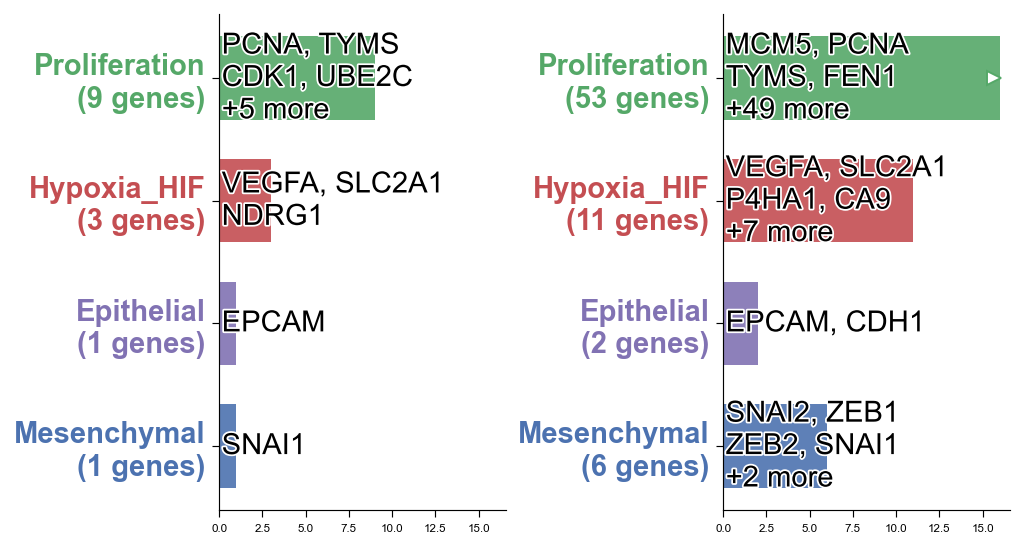

In [24]:
# ═══ Fig 3 — genes per program surviving each shared panel (HD∩v1, HD∩5K) ═══
import numpy as np, matplotlib.pyplot as plt, matplotlib.patheffects as pe
MARKS = ["Proliferation", "Hypoxia_HIF", "Epithelial", "Mesenchymal"]
COL   = {"Epithelial":"#8172b3","Proliferation":"#55a868","Hypoxia_HIF":"#c44e52","Mesenchymal":"#4c72b0"}
# VIM anchors the mesenchymal axis on HD but is absent from both panels; on Xenium the axis is
# carried by EMT-TFs. Ordered so the modelable 5K program (SNAI2/ZEB1/ZEB2) shows first.
MARK_GENES = {"Proliferation": PROGRAMS["Proliferation"],
              "Hypoxia_HIF":   PROGRAMS["Hypoxia_HIF"],
              "Epithelial":    PROGRAMS["Epithelial"],
              "Mesenchymal":   ["SNAI2", "ZEB1", "ZEB2", "SNAI1", "TWIST1", "CDH2"]}
NSHOW, PER = 4, 2

surv = {lab: {m: [g for g in MARK_GENES[m] if g in set(sh)] for m in MARKS}
        for lab, sh in [("v1", shared_HD_v1), ("5K", shared_HD_5K)]}
gmax = max(len(surv[l][m]) for l in surv for m in MARKS)
XCAP = min(gmax, 16)                                   # shared, capped x-scale (both panels comparable)

def _panel(ax, s, title):
    counts = [len(s[m]) for m in MARKS]; y = np.arange(len(MARKS))
    ax.barh(y, [min(c, XCAP) for c in counts], color=[COL[m] for m in MARKS], height=0.68, alpha=0.9)
    for yi, m, c in zip(y, MARKS, counts):
        g = s[m][:NSHOW]; lines = [", ".join(g[i:i+PER]) for i in range(0, len(g), PER)]
        if c > NSHOW: lines.append(f"+{c-NSHOW} more")
        if not g: lines = ["(none)"]
        ax.text(0.15, yi, "\n".join(lines), va="center", ha="left", fontsize=15, linespacing=1.2,
                path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])
        if c > XCAP: ax.plot([XCAP-0.35], [yi], marker=">", ms=7, color="white", mec=COL[m])
    ax.set_yticks(y); ax.set_yticklabels([f"{m}\n({c} genes)" for m, c in zip(MARKS, counts)], fontsize=15)
    for t, m in zip(ax.get_yticklabels(), MARKS): t.set_color(COL[m]); t.set_fontweight("bold")
    ax.set_xlim(0, XCAP+0.6); ax.invert_yaxis(); ax.spines[["top","right"]].set_visible(False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.8), constrained_layout=True)
#_panel(a1, surv["v1"], "HD vs. Xenium v1")
#_panel(a2, surv["5K"], "HD vs. Xenium 5K")
_panel(a1, surv["v1"], "")
_panel(a2, surv["5K"], "")
fig.savefig(OUT_DIR/"fig_program_gene_survival.png"); plt.show()

## 5. Per-platform DenMark pipeline

In [26]:
def _alpha_shape(cells_um, alpha=None):
    """Compact alpha-shape boundary (largest component, holes filled)."""
    import shapely
    from shapely.ops import unary_union, polygonize
    tri = Delaunay(cells_um)
    if alpha is None:  # auto: median edge * 3
        e = np.vstack([tri.simplices[:,[0,1]], tri.simplices[:,[1,2]], tri.simplices[:,[2,0]]])
        d = np.linalg.norm(cells_um[e[:,0]]-cells_um[e[:,1]], axis=1)
        alpha = np.median(d)*3
    keep=[]
    for ia,ib,ic in tri.simplices:
        pa,pb,pc = cells_um[ia],cells_um[ib],cells_um[ic]
        a=np.linalg.norm(pa-pb); b=np.linalg.norm(pb-pc); c=np.linalg.norm(pc-pa)
        s=(a+b+c)/2; ar=max(s*(s-a)*(s-b)*(s-c),1e-12)**0.5
        if a*b*c/(4*ar) < alpha:
            keep += [(ia,ib),(ib,ic),(ic,ia)]
    from shapely.geometry import MultiLineString, LineString
    lines=[LineString([cells_um[i],cells_um[j]]) for i,j in keep]
    poly = unary_union(list(polygonize(unary_union(lines))))
    if poly.geom_type=="MultiPolygon":
        poly=max(poly.geoms, key=lambda g:g.area)
    return shapely.geometry.Polygon(poly.exterior)   

def run_platform(adata, plat, marks, exposure_genes, pitch_um=300.0,
                 method="nuts", per_mark_pitch=None):
    """Fit DenMark ρ for every mark on ONE platform under the UMI-offset model.

    exposure_genes : the y2 exposure = log(total counts over THESE genes per tile).
        Pass the SAME intersected panel on every platform in a comparison so the
        offset denominator is identical across platforms → like-for-like ρ.
    per_mark_pitch : optional {mark: pitch} to coarsen a hard mark's grid (matches HD).
    """
    per_mark_pitch = per_mark_pitch or {}
    cells_um = np.asarray(adata.obsm[COORD_KEY])[:, :2].astype(float)
    tmask = tumour_mask(adata)
    def gcounts(genes):
        gs=[g for g in genes if g in adata.var_names]
        if not gs: return np.zeros(adata.n_obs)
        X = adata[:, gs].layers.get(COUNTS_LAYER, adata[:, gs].X)
        return np.asarray(X.sum(1)).ravel()
    P = _alpha_shape(cells_um)
    expo_cell = gcounts(exposure_genes)                 # per-cell total over exposure genes
    n_expo = len([g for g in exposure_genes if g in adata.var_names])
    def _build(pitch):
        gda, G = build_grids(cells_um, P, pitch)
        gd = gda[gda.type != "exterior"].reset_index(drop=True)
        ix = np.clip(np.searchsorted(G["xedges"], cells_um[:,0], "right")-1, 0, G["NX"]-1)
        iy = np.clip(np.searchsorted(G["yedges"], cells_um[:,1], "right")-1, 0, G["NY"]-1)
        lut = -np.ones((G["NX"], G["NY"]), int)
        lut[gd["i"].values, gd["j"].values] = np.arange(len(gd))
        cg = lut[ix, iy]; sel = (cg >= 0) & tmask
        y1 = np.bincount(cg[sel], minlength=len(gd)).astype(int)
        umi = np.bincount(cg[sel], weights=expo_cell[sel], minlength=len(gd))
        return gd, G, cg, sel, y1, umi
    base = _build(pitch_um); grid_df, G, cg, sel, y1, umi_tile = base
    print(f"{plat:3s}: grid {G['NX']}x{G['NY']} ({G['dx']:.0f}x{G['dy']:.0f}um) | {len(grid_df)} tiles | "
          f"{int(tmask.sum()):,} tumour cells | exposure {n_expo} genes")
    rows=[]
    for name, genes in marks.items():
        gd, Gm, cgm, selm, y1m, umim = (_build(per_mark_pitch[name]) if name in per_mark_pitch else base)
        v = gcounts(genes)
        y2 = np.rint(np.bincount(cgm[selm], weights=v[selm], minlength=len(gd))).astype(int)
        if y2.sum() < 200:
            rows.append(dict(platform=plat, mark=name, n_genes=len(genes), total=int(y2.sum()),
                             pitch=round(Gm["pitch"]), rho_mean=np.nan, rho_lo=np.nan, rho_hi=np.nan,
                             p_pos=np.nan, max_rhat=np.nan, min_ess=np.nan, treedepth_sat_pct=np.nan,
                             divergences=-1, converged=False))
            continue
        data = make_input(gd, y1m, y2, Gm["full_area"], Gm["pitch"], umi=umim)
        fit  = fit_denmark(data, method=method)
        s,_  = rho_summary(fit)
        RHO_DRAWS[(plat, name)] = fit.stan_variable("Astar")[:,1,0]   # for posterior overlay
        sat, ndiv = fit_diagnostics(fit, method)
        s.update(platform=plat, mark=name, n_genes=len(genes), total=int(y2.sum()),
                 pitch=round(Gm["pitch"]), treedepth_sat_pct=round(sat,1), divergences=ndiv,
                 converged=is_converged(s["max_rhat"], s.get("min_ess", np.nan), sat, ndiv))
        rows.append(s)
        flag = "OK" if s["converged"] else "NC"
        print(f"  {plat:3s} {name:16s} rho={s['rho_mean']:+.3f} "
              f"[{s['rho_lo']:+.3f},{s['rho_hi']:+.3f}] Rhat={s['max_rhat']:.3f} "
              f"tot={int(y2.sum())} p{round(Gm['pitch'])} [{flag}]")
    return pd.DataFrame(rows), dict(cells_um=cells_um, tmask=tmask, grid_df=grid_df, G=G, cg=cg,
                                    sel=sel, y1=y1, umi_tile=umi_tile, gcounts=gcounts)

## 5b. QC — tumour mask in space 

 Plot the marker-based mask per platform first

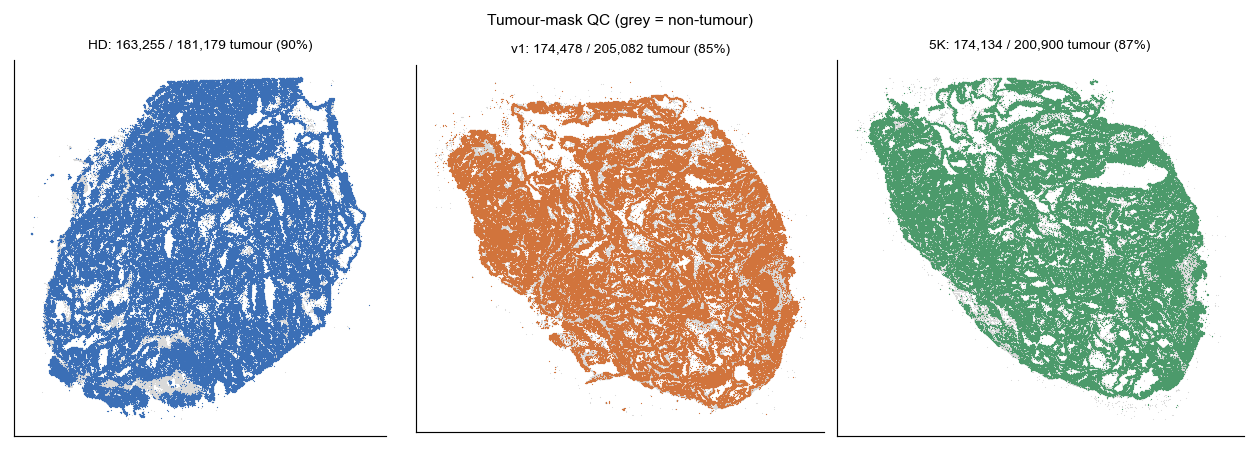

In [29]:
# tumour-mask QC — one panel per platform, tumour cells highlighted
fig, axes = plt.subplots(1, len(adatas), figsize=(3.0*len(adatas), 3.1), constrained_layout=True)
for ax, (plat, a) in zip(np.atleast_1d(axes), adatas.items()):
    xy = np.asarray(a.obsm[COORD_KEY])[:, :2]; t = tumour_mask(a)
    ax.scatter(xy[~t,0], xy[~t,1], s=0.3, c="0.85", linewidths=0, rasterized=True)
    ax.scatter(xy[ t,0], xy[ t,1], s=0.4, c=PLAT_COLORS[plat], linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{plat}: {int(t.sum()):,} / {a.n_obs:,} tumour ({100*t.mean():.0f}%)", fontsize=7)
fig.suptitle("Tumour-mask QC (grey = non-tumour)", fontsize=8)
fig.savefig(OUT_DIR / "fig_qc_tumour_mask.png"); plt.show()

## 6. Run the three comparisons  (fixed 30×30 grid, single clean pass)

`RESULTS` is rebuilt from scratch every run (`res_*` reassigned), so there is no stale-state mixing.
The grid is fixed at 30×30 for every platform via `FORCE_NXNY` in the backend cell; `PITCH` and
per-mark pitch are therefore inert and left empty. The UMI-offset denominator is the **same
intersected panel** on both platforms in each comparison → like-for-like ρ.

In [37]:
METHOD = "nuts"        
assert FORCE_NXNY == (30, 30), "grid must be fixed 30x30 for this comparison"
PITCH  = 300.0         # INERT while FORCE_NXNY is set (kept only for the build_grids signature)
PMP    = {}            # per-mark pitch disabled — one 30x30 grid for every mark, every platform

# ── HD vs Xenium v1  (exposure + programs = genes shared by HD & v1, on BOTH) ──
marks_v1 = marks_for(shared_HD_v1)
print(f"HD vs v1 — {len(marks_v1)} marks on {len(shared_HD_v1)} shared genes | grid 30x30")
res_HD_a, aux_HD_a = run_platform(adatas["HD"], "HD", marks_v1, shared_HD_v1, PITCH, METHOD, PMP)
res_v1,   aux_v1   = run_platform(adatas["v1"], "v1", marks_v1, shared_HD_v1, PITCH, METHOD, PMP)

# ── HD vs Xenium 5K ──
marks_5K = marks_for(shared_HD_5K)
print(f"\nHD vs 5K — {len(marks_5K)} marks on {len(shared_HD_5K)} shared genes | grid 30x30")
res_HD_b, aux_HD_b = run_platform(adatas["HD"], "HD", marks_5K, shared_HD_5K, PITCH, METHOD, PMP)
res_5K,   aux_5K   = run_platform(adatas["5K"], "5K", marks_5K, shared_HD_5K, PITCH, METHOD, PMP)

HD vs v1 — 8 marks on 439 shared genes | grid 30x30
HD : grid 30x30 (815x822um) | 680 tiles | 163,255 tumour cells | exposure 439 genes


18:30:31 - cmdstanpy - INFO - CmdStan start processing
18:30:31 - cmdstanpy - INFO - Chain [1] start processing
18:30:31 - cmdstanpy - INFO - Chain [2] start processing
18:30:31 - cmdstanpy - INFO - Chain [4] start processing
18:30:31 - cmdstanpy - INFO - Chain [3] start processing
18:54:09 - cmdstanpy - INFO - Chain [4] done processing
18:54:48 - cmdstanpy - INFO - Chain [3] done processing
18:55:40 - cmdstanpy - INFO - Chain [2] done processing
18:56:54 - cmdstanpy - INFO - Chain [1] done processing
18:56:54 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
	Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106,

  HD  Proliferation    rho=+0.341 [-0.026,+0.692] Rhat=1.006 tot=720746 p818 [OK]


18:58:00 - cmdstanpy - INFO - CmdStan start processing
18:58:00 - cmdstanpy - INFO - Chain [1] start processing
18:58:00 - cmdstanpy - INFO - Chain [2] start processing
18:58:00 - cmdstanpy - INFO - Chain [3] start processing
18:58:00 - cmdstanpy - INFO - Chain [4] start processing
19:19:40 - cmdstanpy - INFO - Chain [1] done processing
19:19:43 - cmdstanpy - INFO - Chain [2] done processing
19:20:10 - cmdstanpy - INFO - Chain [4] done processing
19:21:07 - cmdstanpy - INFO - Chain [3] done processing
19:21:07 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
	Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106,

  HD  Hypoxia_HIF      rho=-0.413 [-0.737,-0.064] Rhat=1.005 tot=412357 p818 [OK]


...

17:14:53 - cmdstanpy - INFO - CmdStan start processing
17:14:54 - cmdstanpy - INFO - Chain [1] start processing
17:14:54 - cmdstanpy - INFO - Chain [2] start processing
17:14:54 - cmdstanpy - INFO - Chain [3] start processing
17:14:54 - cmdstanpy - INFO - Chain [4] start processing
17:39:40 - cmdstanpy - INFO - Chain [3] done processing
17:41:04 - cmdstanpy - INFO - Chain [4] done processing
17:41:05 - cmdstanpy - INFO - Chain [1] done processing
17:41:51 - cmdstanpy - INFO - Chain [2] done processing
17:41:51 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
	Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106,

  5K  gene:EPCAM       rho=+0.502 [+0.200,+0.788] Rhat=1.008 tot=1267386 p249 [OK]


17:42:46 - cmdstanpy - INFO - CmdStan start processing
17:42:47 - cmdstanpy - INFO - Chain [1] start processing
17:42:47 - cmdstanpy - INFO - Chain [2] start processing
17:42:47 - cmdstanpy - INFO - Chain [3] start processing
17:42:47 - cmdstanpy - INFO - Chain [4] start processing
18:09:30 - cmdstanpy - INFO - Chain [3] done processing
18:10:06 - cmdstanpy - INFO - Chain [1] done processing
18:10:45 - cmdstanpy - INFO - Chain [2] done processing
18:10:46 - cmdstanpy - INFO - Chain [4] done processing
18:10:46 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
	Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106, column 2 to column 33)
Exception: lkj_corr_cholesky_lpdf: Random variable[2] is 0, but must be positive! (in 'DenMark-M2-vararea-umi.stan', line 106,

  5K  gene:PAX8        rho=-0.358 [-0.615,-0.124] Rhat=1.007 tot=883178 p249 [OK]

Three-way — 8 marks on 262 shared genes | grid 30x30


GEOSException: bad allocation

In [75]:
pd.concat([res_HD_a.assign(cmp="HD_v1"), res_v1.assign(cmp="HD_v1"),
           res_HD_b.assign(cmp="HD_5K"), res_5K.assign(cmp="HD_5K")], ignore_index=True
          ).to_csv(OUT_DIR / "denmark_rho_pairwise_umi.csv", index=False)
print("saved pairwise table → ", OUT_DIR / "denmark_rho_pairwise_umi.csv")

saved pairwise table →  xplatform_out\denmark_rho_pairwise_umi.csv


In [66]:
import pandas as pd
from pathlib import Path
OUT_DIR = globals().get("OUT_DIR", Path(f"{OUTPUT_DIR}/xplatform_out")); OUT_DIR.mkdir(parents=True, exist_ok=True)

# gate: R-hat and divergences unchanged; ESS floor relaxed 200 -> 150 (accepts v1 Hypoxia_HIF,
# ESS 173, R-hat 1.03, 2 div). Recompute the flag from the diagnostics already in each table.
RHAT_MAX, ESS_MIN, MAXDIV = 1.1, 150, 20
def _conv(r):
    rhat = r.get("max_rhat", float("nan")); ess = r.get("min_ess", float("nan")); ndiv = r.get("divergences", -1)
    return bool(pd.notna(rhat) and rhat < RHAT_MAX
                and (pd.isna(ess) or ess > ESS_MIN)
                and (0 <= ndiv <= MAXDIV))

# save each result table that exists in memory (with refreshed `converged`)
for name in ["res_HD_a", "res_v1", "res_HD_b", "res_5K"]:
    if name in globals():
        df = globals()[name].copy()
        df["converged"] = df.apply(_conv, axis=1)
        globals()[name] = df
        df.to_csv(OUT_DIR / f"{name}.csv", index=False)
        print("saved", name, df.shape)

# combined pairwise table (what the run cell would have written)
parts = []
if "res_HD_a" in globals(): parts.append(res_HD_a.assign(cmp="HD_v1"))
if "res_v1"   in globals(): parts.append(res_v1.assign(cmp="HD_v1"))
if "res_HD_b" in globals(): parts.append(res_HD_b.assign(cmp="HD_5K"))
if "res_5K"   in globals(): parts.append(res_5K.assign(cmp="HD_5K"))
if parts:
    pd.concat(parts, ignore_index=True).to_csv(OUT_DIR / "denmark_rho_pairwise_umi.csv", index=False)
    print("saved denmark_rho_pairwise_umi.csv")

saved res_HD_a (8, 14)
saved res_v1 (8, 14)
saved res_HD_b (12, 14)
saved res_5K (12, 14)
saved denmark_rho_pairwise_umi.csv


In [68]:
import pickle
if "RHO_DRAWS" in globals():
    with open(OUT_DIR / "rho_draws.pkl", "wb") as f:
        pickle.dump(RHO_DRAWS, f)
    print("saved rho_draws.pkl", len(RHO_DRAWS), "keys")

saved rho_draws.pkl 32 keys


In [70]:
import pandas as pd, pickle
from pathlib import Path
OUT_DIR = Path(f"{OUTPUT_DIR}/xplatform_out")

RHAT_MAX, ESS_MIN, MAXDIV = 1.1, 150, 20
def _conv(r):
    rhat = r.get("max_rhat", float("nan")); ess = r.get("min_ess", float("nan")); ndiv = r.get("divergences", -1)
    return bool(pd.notna(rhat) and rhat < RHAT_MAX
                and (pd.isna(ess) or ess > ESS_MIN)
                and (0 <= ndiv <= MAXDIV))

res_HD_a = pd.read_csv(OUT_DIR/"res_HD_a.csv")
res_v1   = pd.read_csv(OUT_DIR/"res_v1.csv")
res_HD_b = pd.read_csv(OUT_DIR/"res_HD_b.csv")
res_5K   = pd.read_csv(OUT_DIR/"res_5K.csv")
for _df in (res_HD_a, res_v1, res_HD_b, res_5K):
    _df["converged"] = _df.apply(_conv, axis=1)
RHO_DRAWS = pickle.load(open(OUT_DIR/"rho_draws.pkl","rb"))

In [72]:
for lab, hd, x in [("HD∩v1", res_HD_a, res_v1), ("HD∩5K", res_HD_b, res_5K)]:
    m = hd.merge(x, on="mark", suffixes=("_HD","_X"))
    prog = m[~m["mark"].str.startswith("gene:")]
    print(f"\n{lab}:")
    print(prog[["mark","rho_mean_HD","rho_mean_X","converged_HD","converged_X"]].to_string(index=False))


HD∩v1:
         mark  rho_mean_HD  rho_mean_X  converged_HD  converged_X
Proliferation     0.340993    0.364000          True         True
  Hypoxia_HIF    -0.412877   -0.260714          True         True

HD∩5K:
         mark  rho_mean_HD  rho_mean_X  converged_HD  converged_X
Proliferation     0.425458    0.373503          True         True
  Hypoxia_HIF    -0.462647   -0.263791          True         True
   Epithelial     0.176130    0.415460          True         True
  Mesenchymal    -0.494975   -0.669654          True         True


## 7. Figure-style

In [81]:
# ═══ Main-figure forest: 4 programs only (HD vs Xenium v1, HD vs 5K) ═══
PROGRAMS_ONLY = ["Proliferation", "Hypoxia_HIF", "Epithelial", "Mesenchymal"]
def prog_only(df):
    return df[df["mark"].isin(PROGRAMS_ONLY)].copy()

In [ ]:
# add the posterior mean number into the figures 

In [154]:
# Fig: paired forest - rho per mark, HD vs Xenium (all points filled, ρ labelled)
from matplotlib.lines import Line2D
def paired_forest(resHD, resX, xname, title, fname,
                  title_fs=8, xlabel_fs=7, ytick_fs=7, xtick_fs=6, legend_fs=6, val_fs=6):
    d = resHD.merge(resX, on="mark", suffixes=("_HD", f"_{xname}")).dropna(subset=["rho_mean_HD"])
    d = d.sort_values("rho_mean_HD"); y = np.arange(len(d)); h=0.36
    fig, ax = plt.subplots(figsize=(3.4, 0.28*len(d)+0.9))
    for off, plat, suf in [(+h/2,"HD","_HD"), (-h/2,xname,f"_{xname}")]:
        for k,(_,r) in enumerate(d.iterrows()):
            mean, hi = r[f"rho_mean{suf}"], r[f"rho_hi{suf}"]
            ax.errorbar(mean, y[k]+off,
                        xerr=[[max(mean-r[f"rho_lo{suf}"],0)],
                              [max(hi-mean,0)]],
                        fmt="o", ms=3.4, lw=0.8, capsize=1.5, color=PLAT_COLORS[plat],
                        mfc=PLAT_COLORS[plat], mec=PLAT_COLORS[plat])
            ax.annotate(f"{mean:+.2f}", (hi, y[k]+off), xytext=(3, 0),
                        textcoords="offset points", va="center", ha="left",
                        fontsize=val_fs, color=PLAT_COLORS[plat])
    ax.axvline(0, color="0.4", lw=0.6, ls="--")
    ax.set_yticks(y); ax.set_yticklabels([m.replace("gene:","") for m in d["mark"]], fontsize=ytick_fs)
    ax.tick_params(axis="x", labelsize=xtick_fs)
    ax.set_xlabel("DenMark rho", fontsize=xlabel_fs)
    ax.set_title(title, fontsize=title_fs)
    # headroom on the right so the labels aren't clipped
    x0, x1 = ax.get_xlim(); ax.set_xlim(x0, x1 + 0.15*(x1 - x0))
    ax.legend(handles=[Line2D([0],[0],marker="o",ls="none",mfc=PLAT_COLORS["HD"],mec=PLAT_COLORS["HD"],label="Visium HD"),
                       Line2D([0],[0],marker="o",ls="none",mfc=PLAT_COLORS[xname],mec=PLAT_COLORS[xname],label=f"Xenium {xname}")],
              loc="lower right", frameon=False, fontsize=legend_fs)
    plt.tight_layout(); fig.savefig(OUT_DIR / fname); return fig

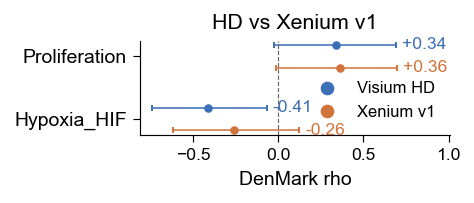

In [160]:
FS = dict(title_fs=11, xlabel_fs=10, ytick_fs=10, xtick_fs=9, legend_fs=8.5, val_fs=9)
paired_forest(prog_only(res_HD_a), prog_only(res_v1), "v1",
              "HD vs Xenium v1", "fig_forest_HD_v1_programs.png", **FS); plt.show()

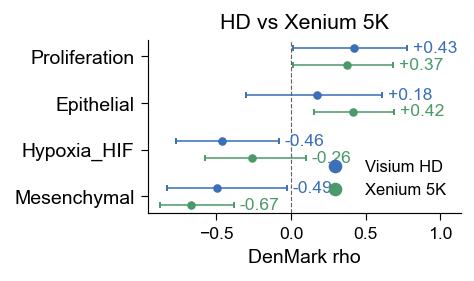

In [162]:

paired_forest(prog_only(res_HD_b), prog_only(res_5K), "5K",
              "HD vs Xenium 5K", "fig_forest_HD_5K_programs.png", **FS); plt.show()

In [99]:
import pickle
def _slim(a):  # keep the arrays used for plotting; drop the un-picklable gcounts closure
    return {k: a[k] for k in ["cells_um","tmask","grid_df","G","cg","sel","y1","umi_tile"] if k in a}

aux_all = {"HD_v1_HD": _slim(aux_HD_a), "HD_v1_v1": _slim(aux_v1),
           "HD_5K_HD": _slim(aux_HD_b), "HD_5K_5K": _slim(aux_5K)}
with open(OUT_DIR/"aux_all.pkl", "wb") as f:
    pickle.dump(aux_all, f)
print("saved aux_all.pkl", list(aux_all))

saved aux_all.pkl ['HD_v1_HD', 'HD_v1_v1', 'HD_5K_HD', 'HD_5K_5K']


In [103]:
need = ["res_HD_a.csv","res_v1.csv","res_HD_b.csv","res_5K.csv",
        "denmark_rho_pairwise_umi.csv","rho_draws.pkl","aux_all.pkl"]
have = {p.name for p in OUT_DIR.glob("*")}
for f in need:
    print(("OK  " if f in have else "MISSING "), f)

OK   res_HD_a.csv
OK   res_v1.csv
OK   res_HD_b.csv
OK   res_5K.csv
OK   denmark_rho_pairwise_umi.csv
OK   rho_draws.pkl
OK   aux_all.pkl


In [105]:
import pickle
session = {
    "shared_HD_v1": list(shared_HD_v1), "shared_HD_5K": list(shared_HD_5K),
    "shared_all": list(shared_all), "PROGRAMS": PROGRAMS,
    "PLAT_COLORS": PLAT_COLORS, "COORD_KEY": COORD_KEY, "COUNTS_LAYER": COUNTS_LAYER,
}
pickle.dump(session, open(OUT_DIR/"session_meta.pkl","wb"))
print("saved session_meta.pkl")

saved session_meta.pkl


In [107]:
for p in [HD_H5AD, XENIUM_V1_DIR, XENIUM_5K_DIR]:
    print(Path(p).exists(), p)

True <DATA_DIR>\visium_ovarian\results\tables\visium_hd_ovarian_cancer_annotated.h5ad
True <DATA_DIR>\Revision-R1\VisiumHD-Breast_Cancer\Xenium V1
True <DATA_DIR>\Revision-R1\VisiumHD-Breast_Cancer\Xenium 5K


In [ ]:
# saved the necessary files. 